# Basic Library Functionality

This notebook contains examples of basic tableau functionality, such as noiseless simulation and measurement in both prime and composite dimensions.

It also demonstrates state vector and density matrix simulation.

Note that these examples do not cover the full functionality of the library. For more information, please refer to the documentation and other examples.

In [1]:
import numpy as np
import quickqudits as qq

## Create a circuit

In [2]:
n, d = 4, 3

qc = qq.QuantumCircuit(n, d, name="example_circuit")

qc.S(0)
qc.CX(0, 1)
qc.H(0)
qc.S(1)
qc.Hdag(2)
qc.Xdag(2)
qc.CZ(1, 3)
qc.SWAP(0, 2)
qc.CXdag(0, 2)
qc.CZ(2, 0)
qc.Hdag(3)
qc.Y(3)
qc.CXdag(3, 0)
qc.CZ(0, 1)

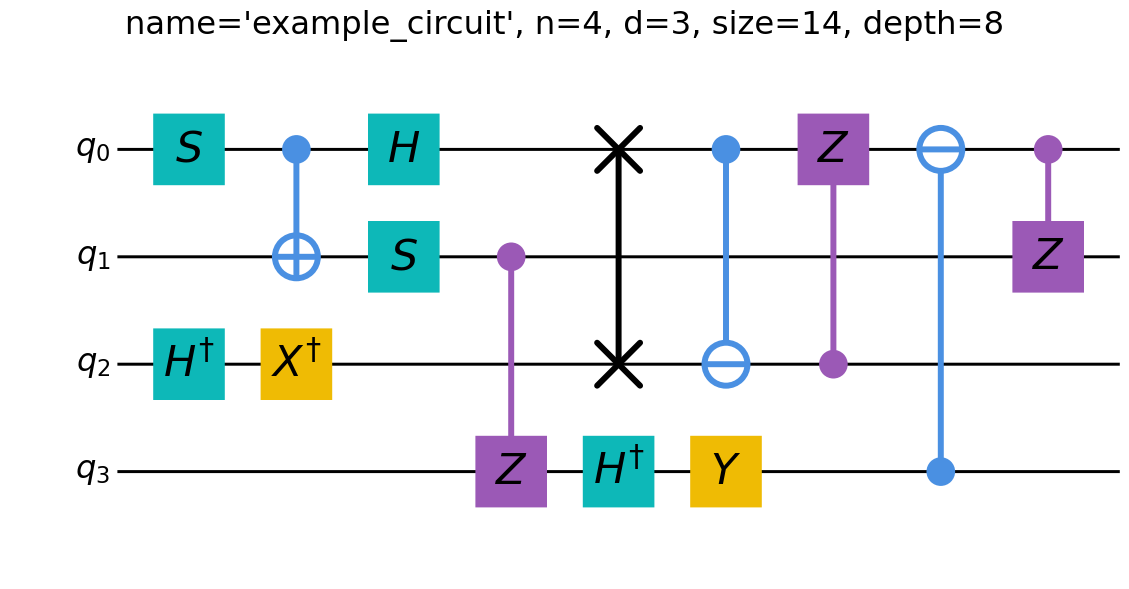

In [3]:
qc.draw(show_info=True)

## Tableau Simulation & Measurement

## Prime d

In [4]:
tab = qq.Tableau(n, d, full=True)

print(tab)

#  | x0 x1 x2 x3 | z0 z1 z2 z3 | τ
──────────────────────────────────
d0 |  1  0  0  0 |  0  0  0  0 | 0
d1 |  0  1  0  0 |  0  0  0  0 | 0
d2 |  0  0  1  0 |  0  0  0  0 | 0
d3 |  0  0  0  1 |  0  0  0  0 | 0
----------------------------------
s0 |  0  0  0  0 |  1  0  0  0 | 0
s1 |  0  0  0  0 |  0  1  0  0 | 0
s2 |  0  0  0  0 |  0  0  1  0 | 0
s3 |  0  0  0  0 |  0  0  0  1 | 0


In [5]:
tab.print_stabilizers()

#  | phase | 0 | 1 | 2 | 3
──────────────────────────
d0 | 1     | X | I | I | I
d1 | 1     | I | X | I | I
d2 | 1     | I | I | X | I
d3 | 1     | I | I | I | X
--------------------------
s0 | 1     | Z | I | I | I
s1 | 1     | I | Z | I | I
s2 | 1     | I | I | Z | I
s3 | 1     | I | I | I | Z


In [6]:
tab.apply_circuit(qc) # applied in place

Tableau(n=4, d=3, full=True, rows=8)

In [7]:
tab.print_stabilizers(show_omegas=True)

#  | phase | 0   | 1  | 2   | 3 
────────────────────────────────
d0 | ω²    | X²Z | X  | X²Z | X 
d1 | 1     | X²Z | X  | I   | X 
d2 | ω²    | Z²  | I  | I   | Z²
d3 | ω     | I   | Z  | I   | Z²
--------------------------------
s0 | 1     | Z²  | I  | X²  | Z²
s1 | 1     | Z   | Z  | X   | Z 
s2 | ω²    | XZ² | Z  | X²Z | Z²
s3 | ω     | X²  | Z² | I   | X 


In [8]:
tab[1]

array([2, 1, 0, 1, 1, 0, 0, 0, 0], dtype=int8)

In [9]:
np.round(tab.to_statevector(), 4)

array([ 0.1925-0.j    , -0.0962+0.1667j, -0.0962-0.1667j,  0.1925-0.j    ,
       -0.0962-0.1667j, -0.0962+0.1667j,  0.1925-0.j    ,  0.1925+0.j    ,
        0.1925-0.j    , -0.    -0.j    ,  0.    +0.j    ,  0.    +0.j    ,
       -0.    -0.j    , -0.    +0.j    , -0.    +0.j    , -0.    +0.j    ,
       -0.    -0.j    ,  0.    -0.j    ,  0.    +0.j    ,  0.    +0.j    ,
       -0.    -0.j    , -0.    +0.j    ,  0.    -0.j    ,  0.    +0.j    ,
       -0.    -0.j    ,  0.    +0.j    , -0.    -0.j    ,  0.1925-0.j    ,
       -0.0962+0.1667j, -0.0962-0.1667j, -0.0962+0.1667j,  0.1925-0.j    ,
       -0.0962-0.1667j, -0.0962-0.1667j, -0.0962-0.1667j, -0.0962-0.1667j,
        0.    +0.j    , -0.    -0.j    , -0.    -0.j    ,  0.    +0.j    ,
        0.    +0.j    ,  0.    -0.j    , -0.    -0.j    , -0.    -0.j    ,
       -0.    -0.j    , -0.    +0.j    ,  0.    -0.j    , -0.    +0.j    ,
        0.    -0.j    ,  0.    +0.j    , -0.    +0.j    ,  0.    +0.j    ,
       -0.    -0.j    , -

In [10]:
_, mmt_results = tab.measure(qudits_to_measure=[0, 2], in_place=False, seed=42)

mmt_results

{0: 0, 2: 2}

In [11]:
_, mmt_results = tab.measure_all(in_place=False, seed=42)

mmt_results

array([0, 0, 2, 1])

In [12]:
tab.measurement_kinds()

{0: 'rand', 1: 'det', 2: 'rand', 3: 'rand'}

In [13]:
_, res = tab.measure(qudits_to_measure=3, desired=2)

print(f"Set qudit 3 outcome to the desired outcome (2): {res}")

Set qudit 3 outcome to the desired outcome (2): {3: (2, 'rand')}


**Reduced Tableau**

In [14]:
print(f"Tableau before the measurement:\n")

print(tab)

Tableau before the measurement:

#  | x0 x1 x2 x3 | z0 z1 z2 z3 | τ
──────────────────────────────────
d0 |  2  1  2  1 |  1  0  1  0 | 4
d1 |  2  1  0  1 |  1  0  0  0 | 0
d2 |  0  0  0  0 |  2  0  0  2 | 4
d3 |  0  0  0  0 |  0  1  0  2 | 2
----------------------------------
s0 |  0  0  2  0 |  2  0  0  2 | 0
s1 |  0  0  1  0 |  1  1  0  1 | 0
s2 |  1  0  2  0 |  2  1  1  2 | 4
s3 |  2  0  0  1 |  0  2  0  0 | 2


In [15]:
print(f"Reduced Tableau:\n")

post_tab, post_result = tab.post_measure(qudits_to_measure=0, seed=42)

print(post_tab)

print(f"\nMeasurement result on qudit 0: {post_result}")

Reduced Tableau:

#  | x0 x1 x2 | z0 z1 z2 | τ
────────────────────────────
d0 |  1  1  1 |  1  2  2 | 2
d1 |  1  2  1 |  1  1  2 | 0
d2 |  0  0  0 |  1  0  2 | 2
----------------------------
s0 |  0  2  0 |  0  0  2 | 0
s1 |  0  1  0 |  1  0  1 | 0
s2 |  0  2  1 |  0  1  2 | 0

Measurement result on qudit 0: {0: 0}


In [16]:
print(f"Reduced Tableau:\n")

post_tab, post_result = tab.post_measure(qudits_to_measure=(1, 2), seed=22)

print(post_tab)

print(f"\nMeasurement results on qudits 1 and 2: {post_result}")

Reduced Tableau:

#  | x0 x1 | z0 z1 | τ
──────────────────────
d0 |  0  0 |  2  0 | 2
d1 |  0  0 |  0  2 | 2
----------------------
s0 |  1  0 |  0  0 | 4
s1 |  0  1 |  0  0 | 0

Measurement results on qudits 1 and 2: {1: 0, 2: 2}


**Sample measurements**

In [17]:
res = tab.sample_measurements(shots=5, seed=42)

print(res)

[[1 0 0 0]
 [0 0 1 1]
 [0 0 0 0]
 [2 0 1 0]
 [2 0 0 1]]


**Convert to probability vector (Monte Carlo)**

In [18]:
tab.to_probvector(shots=1_000_000, seed=42)

array([0.036866, 0.037196, 0.037167, 0.036846, 0.037307, 0.037048,
       0.03712 , 0.037063, 0.037046, 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.03713 , 0.037346, 0.037205,
       0.037224, 0.037224, 0.037117, 0.036761, 0.036698, 0.037159,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.037016, 0.036796, 0.037149, 0.03708 , 0.036661, 0.037119,
       0.036789, 0.037009, 0.036858, 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      ])

**Convert to probability vector (exact)**

In [19]:
tab.to_probvector_exact()

array([0.03703704, 0.03703704, 0.03703704, 0.03703704, 0.03703704,
       0.03703704, 0.03703704, 0.03703704, 0.03703704, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.03703704, 0.03703704, 0.03703704,
       0.03703704, 0.03703704, 0.03703704, 0.03703704, 0.03703704,
       0.03703704, 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.03703704,
       0.03703704, 0.03703704, 0.03703704, 0.03703704, 0.03703704,
       0.03703704, 0.03703704, 0.03703704, 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

## Composite d

In order to measure in composite d, we need to create an instance of the `CompositeTableau` class, which inherits from the `Tableau` class.

Please note that post-measurement (after the `measure(_all)` method) and reduced tableaus are not implemented for this class.

While circuit simulation works in `Tableau` for composite d, if you intend to measure, you need to use `CompositeTableau`.

**Create a small random circuit**

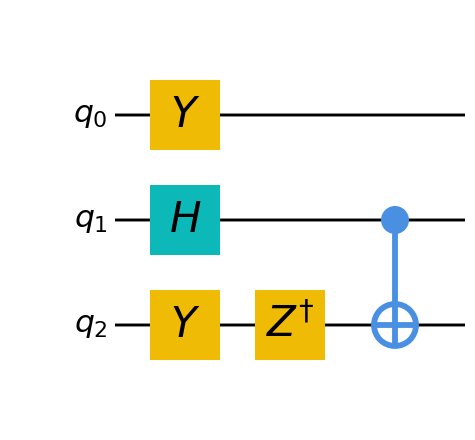

In [20]:
n = 3
d = 12

qc_rand = qq.utils.random_circuit(n, d, max_size=5, max_depth=5, seed=42)

qc_rand.draw()

In [21]:
tab_composite = qq.CompositeTableau(n, d, full=True)

tab_composite.apply_circuit(qc_rand, print_tableau=True)

Initial tableau:
#  | x0 x1 x2 | z0 z1 z2 | τ
────────────────────────────
d0 |  1  0  0 |  0  0  0 | 0
d1 |  0  1  0 |  0  0  0 | 0
d2 |  0  0  1 |  0  0  0 | 0
----------------------------
s0 |  0  0  0 |  1  0  0 | 0
s1 |  0  0  0 |  0  1  0 | 0
s2 |  0  0  0 |  0  0  1 | 0

--- Applying Y on qudit 2 ---
#  | x0 x1 x2 | z0 z1 z2 |  τ
─────────────────────────────
d0 |  1  0  0 |  0  0  0 |  0
d1 |  0  1  0 |  0  0  0 |  0
d2 |  0  0  1 |  0  0  0 |  2
-----------------------------
s0 |  0  0  0 |  1  0  0 |  0
s1 |  0  0  0 |  0  1  0 |  0
s2 |  0  0  0 |  0  0  1 | 22

--- Applying Z† on qudit 2 ---
#  | x0 x1 x2 | z0 z1 z2 |  τ
─────────────────────────────
d0 |  1  0  0 |  0  0  0 |  0
d1 |  0  1  0 |  0  0  0 |  0
d2 |  0  0  1 |  0  0  0 |  0
-----------------------------
s0 |  0  0  0 |  1  0  0 |  0
s1 |  0  0  0 |  0  1  0 |  0
s2 |  0  0  0 |  0  0  1 | 22

--- Applying H on qudit 1 ---
#  | x0 x1 x2 | z0 z1 z2 |  τ
─────────────────────────────
d0 |  1  0  0 |  0  0  0 |  

Tableau(n=3, d=12, full=True, rows=6)

In [22]:
mmt_results = tab_composite.measure(qudits_to_measure=[0, 2], in_place=False, seed=42)

print(mmt_results)

{0: 1, 2: 2}


In [23]:
mmt_results = tab_composite.measure_all(in_place=False, seed=42)

print(mmt_results)

[1 1 2]


In [24]:
res = tab_composite.sample_measurements(shots=5, seed=42)

print(res)

[[ 1  1  2]
 [ 1  9 10]
 [ 1  7  8]
 [ 1  5  6]
 [ 1  5  6]]


**Convert to probvector (use d=4)**

In [25]:
qc_rand.change_dim(4)

tab_composite2 = qq.CompositeTableau(n, 4)
tab_composite2.apply_circuit(qc_rand)

Tableau(n=3, d=4, full=True, rows=6)

In [26]:
probvector_tab = tab_composite2.to_probvector(shots=1_000_000, seed=42)

In [27]:
probvector_analytic = np.abs(tab_composite2.to_statevector()) ** 2

In [28]:
probvector_tab

array([0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.250326,
       0.      , 0.      , 0.      , 0.      , 0.249838, 0.      ,
       0.      , 0.      , 0.      , 0.250451, 0.249385, 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      , 0.      , 0.      ,
       0.      , 0.      , 0.      , 0.      ])

In [29]:
probvector_analytic

array([0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.25, 0.  , 0.  , 0.  , 0.  ,
       0.25, 0.  , 0.  , 0.  , 0.  , 0.25, 0.25, 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

## Statevector simulation

In [30]:
n = 3
d = 4

qc_rand2 = qq.utils.random_circuit(n, d, max_size=5, max_depth=5, seed=22)

psi, _ = qc_rand2.execute(print_state=False)

print(f'Final state vector:\n {np.round(psi, 4)}')

print(f'\nFinal prob vector:\n {np.round(np.abs(psi)**2, 4)}')

Final state vector:
 [ 0.    +0.j      0.3536-0.3536j  0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j     -0.3536-0.3536j  0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j     -0.3536+0.3536j  0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.3536+0.3536j  0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j
  0.    +0.j      0.    +0.j      0.    +0.j      0.    +0.j    

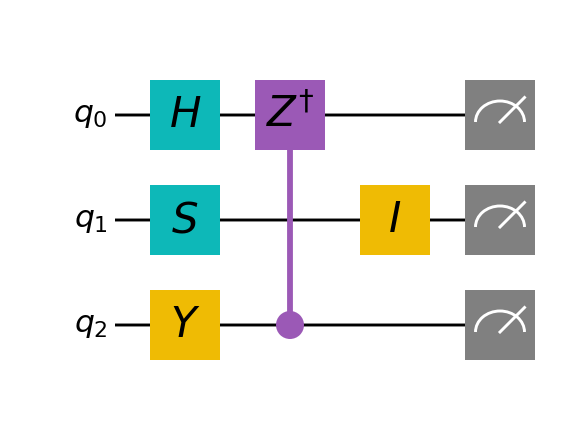

{0: 3, 1: 0, 2: 1}

In [31]:
qc_rand_m = qc_rand2.copy()

qc_rand_m.measure_all()
qc_rand_m.draw()

psi2, res = qc_rand_m.execute()
res

## Density Matrix simulation

In [32]:
final_rho = qc_rand2.execute_density_matrix()
prob_vector_dm = qq.utils.density_matrix_to_probvector(final_rho)

prob_vector_dm

array([0.  , 0.25, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.25, 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.25, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.25, 0.  , 0.  , 0.  , 0.  , 0.  ,
       0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

## Schmidt Rank Vector

**GHZ State**

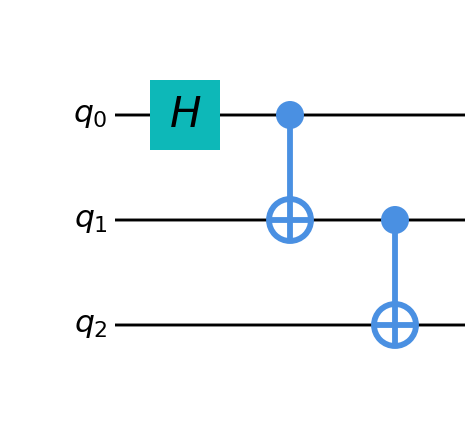

k-vector: [1 1 1]
Schmidt rank vector: [2 2 2]


In [33]:
n, d = 3, 2

qc = qq.QuantumCircuit(n, d)
qc.H(0)
qc.CX(0, 1)
qc.CX(1, 2)
qc.draw()

tab = qq.Tableau(n, d, full=True)

tab.apply_circuit(qc)

k, r = qq.utils.schmidt_rank_vector(tab)

print(f'k-vector: {k}')
print(f'Schmidt rank vector: {r}')

**Partion into two sets of size 2**

In [34]:
n, d = 4, 5

qc = qq.QuantumCircuit(n, d)
qc.H(0)
qc.CX(0, 1)
qc.CX(0, 2)

tab = qq.Tableau(n, d, full=True)
tab.apply_circuit(qc)

k, r = qq.utils.schmidt_rank(tab, {0, 1}, {2, 3})

print(f'k: {k}')
print(f'Schmidt rank: {r}')

k: 1
Schmidt rank: 5


## Save/load tableau & circuit

In [35]:
n, d = 3, 5

qc = qq.QuantumCircuit(n, d)
qc.H(0)
qc.CX(0, 1)
qc.CX(0, 2)

tab = qq.Tableau(n, d, full=True)
tab.apply_circuit(qc)

Tableau(n=3, d=5, full=True, rows=6)

In [36]:
print(tab)
qq.io.save_tableau(tab, path="test_tab")

tab_load = qq.io.load_tableau(path="test_tab")
print()
print(tab_load)
print(tab == tab_load)

#  | x0 x1 x2 | z0 z1 z2 | τ
────────────────────────────
d0 |  0  0  0 |  1  0  0 | 0
d1 |  0  1  0 |  0  0  0 | 0
d2 |  0  0  1 |  0  0  0 | 0
----------------------------
s0 |  4  4  4 |  0  0  0 | 0
s1 |  0  0  0 |  4  1  0 | 0
s2 |  0  0  0 |  4  0  1 | 0

#  | x0 x1 x2 | z0 z1 z2 | τ
────────────────────────────
d0 |  0  0  0 |  1  0  0 | 0
d1 |  0  1  0 |  0  0  0 | 0
d2 |  0  0  1 |  0  0  0 | 0
----------------------------
s0 |  4  4  4 |  0  0  0 | 0
s1 |  0  0  0 |  4  1  0 | 0
s2 |  0  0  0 |  4  0  1 | 0
True


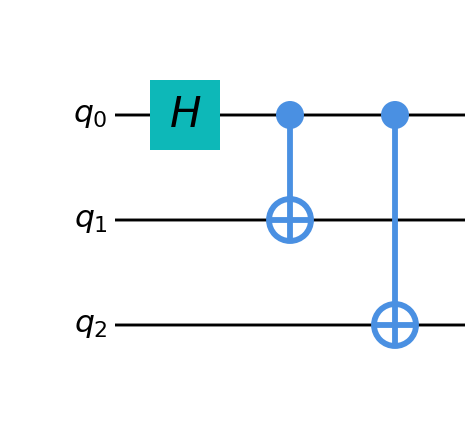

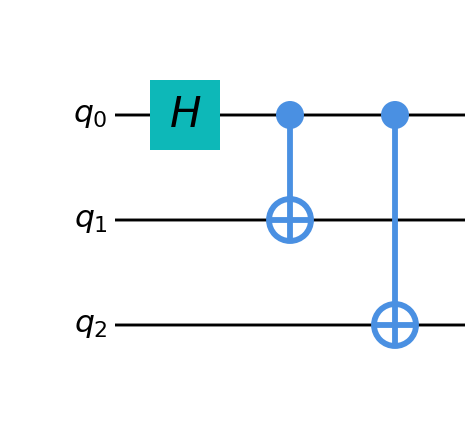

In [37]:
qc.draw()
qq.io.save_circuit(qc, path="test_c")

qc_load = qq.io.load_circuit(path="test_c")
qc_load.draw()